<div dir="rtl" style="text-align:right; font-family:Tahoma, sans-serif; line-height:1.9">
<h1 style="color:#0F2A4A">نوت‌بوک ۲ — درخت تصمیم (Decision Tree)</h1>
<h2 style="color:#0E7490">Decision Tree Classifier</h2>
<p>درخت تصمیم نمونه‌ها را از ریشه به برگ دسته‌بندی می‌کند: <b>گره داخلی = آزمون یک ویژگی، شاخه = مقدار پاسخ، برگ = کلاس</b>. مزیت بزرگ: کاملاً تفسیرپذیر و قابل تبدیل به قوانین IF-THEN.</p>
<p>در این نوت‌بوک:</p>
<ul><li>مثال کلاسیک تنیس: ساخت درخت و استخراج قوانین</li><li>اجرا روی Iris + رسم درخت و اهمیت ویژگی‌ها</li></ul>
<p style="color:#45607A; font-size:13px">همراه ارائه درس «داده‌کاوی و یادگیری ماشین» — برای اجرا در Google Colab: هر سلول را با <b>Shift+Enter</b> اجرا کنید و پارامترها را آزادانه تغییر دهید.</p>
<hr style="border:0;border-top:1px dashed #B7DFEA;margin:10px 0">
<p style="background:#EBF7FA;border:1px solid #B7DFEA;border-radius:8px;padding:10px 12px">
🛠 <b>راهنمای استفاده:</b> همهٔ کدها در <b>Google Colab</b> اجرا می‌شوند — بدون نصبِ پایتون یا کتابخانه؛ فقط مرورگر و اینترنت (اجرای هر سلول: <b>Shift+Enter</b> یا منوی Runtime ▸ Run all).<br>
🐍 <b>یادگیری پایتون، از صفر:</b> <a href="https://www.w3schools.com/python/default.asp">W3Schools — Python Tutorial</a> — آموزش تعاملی و رایگان؛ مثال‌ها را همان‌جا اجرا و ویرایش کنید.<br>
📝 <b>هر سلول:</b> توضیح فارسی در بالای سلول و کامنت‌های فارسی داخل کد آمده است؛ خروجی‌ها هم از قبل ذخیره شده‌اند.
</p>
</div>

In [1]:
# تنظیمات اولیه: واردکردن کتابخانه‌ها + پالت رنگی و ظاهر یکسان نمودارها
import numpy as np, pandas as pd, matplotlib.pyplot as plt
TEAL, NAVY, AMBER = "#0E7490", "#0F2A4A", "#B45309"
plt.rcParams.update({"figure.facecolor":"white","axes.grid":True,"grid.color":"#D8E2EC",
    "axes.edgecolor":"#94A3B8","axes.labelcolor":"#0F2A4A","text.color":"#0F2A4A",
    "axes.titlecolor":"#0F2A4A","axes.titleweight":"bold","legend.frameon":False,
    "xtick.color":"#334155","ytick.color":"#334155"})
print("libraries ready")

libraries ready


<div dir="rtl" style="text-align:right; font-family:Tahoma, sans-serif; line-height:1.9">
<h2 style="color:#0F2A4A">۱) مثال کلاسیک: امروز تنیس بازی کنیم؟</h2>
</div>

In [2]:
# جدول تنیس (مثال کلاسیک درس): ۱۴ روز — Outlook / Humidity / Wind / Play
tennis = pd.DataFrame({
    "Outlook":  ["Sunny","Sunny","Overcast","Rain","Rain","Rain","Overcast",
                 "Sunny","Sunny","Rain","Sunny","Overcast","Overcast","Rain"],
    "Humidity": ["High","High","High","High","Normal","Normal","Normal",
                 "High","Normal","Normal","Normal","High","Normal","High"],
    "Wind":     ["Weak","Strong","Weak","Weak","Weak","Strong","Strong",
                 "Weak","Weak","Weak","Strong","Strong","Weak","Strong"],
    "Play":     ["No","No","Yes","Yes","Yes","No","Yes",
                 "No","Yes","Yes","Yes","Yes","Yes","No"]})
tennis

,Outlook,Humidity,Wind,Play
0,Sunny,High,Weak,No
1,Sunny,High,Strong,No
2,Overcast,High,Weak,Yes
3,Rain,High,Weak,Yes
4,Rain,Normal,Weak,Yes
5,Rain,Normal,Strong,No
6,Overcast,Normal,Strong,Yes
7,Sunny,High,Weak,No
8,Sunny,Normal,Weak,Yes
9,Rain,Normal,Weak,Yes


In [3]:
# ساخت درخت روی جدول تنیس و نمایش قوانین IF-THEN با export_text — همان خروجی اسلاید ۹
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.preprocessing import OrdinalEncoder

enc = OrdinalEncoder()
X_t = enc.fit_transform(tennis[["Outlook","Humidity","Wind"]])
y_t = (tennis.Play == "Yes").astype(int)

tree_t = DecisionTreeClassifier(random_state=42).fit(X_t, y_t)
print(export_text(tree_t, feature_names=["Outlook","Humidity","Wind"]))

|--- Outlook <= 0.50
|   |--- class: 1
|--- Outlook >  0.50
|   |--- Humidity <= 0.50
|   |   |--- Outlook <= 1.50
|   |   |   |--- Wind <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- Wind >  0.50
|   |   |   |   |--- class: 1
|   |   |--- Outlook >  1.50
|   |   |   |--- class: 0
|   |--- Humidity >  0.50
|   |   |--- Wind <= 0.50
|   |   |   |--- Outlook <= 1.50
|   |   |   |   |--- class: 0
|   |   |   |--- Outlook >  1.50
|   |   |   |   |--- class: 1
|   |   |--- Wind >  0.50
|   |   |   |--- class: 1



<div dir="rtl" style="text-align:right; font-family:Tahoma, sans-serif; line-height:1.9">
<p>خط اول یعنی: <code>IF (Outlook = Sunny) AND (Humidity = High) THEN Play = No</code> — دقیقاً مبحث «طبقه‌بندی قاعده‌محور» اسلایدهای درس!</p>
</div>

<div dir="rtl" style="text-align:right; font-family:Tahoma, sans-serif; line-height:1.9">
<h2 style="color:#0F2A4A">۲) درخت تصمیم روی Iris</h2>
</div>

In [4]:
# درخت تصمیم روی Iris با max_depth=۳ — دقت آموزش و آزمون
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

iris = load_iris()
X, y = iris.data, iris.target
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.15,
                                          random_state=42, stratify=y)

tree = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_tr, y_tr)
print("Train accuracy:", tree.score(X_tr, y_tr))
print("Test accuracy :", tree.score(X_te, y_te))

Train accuracy: 0.984251968503937
Test accuracy : 0.9565217391304348


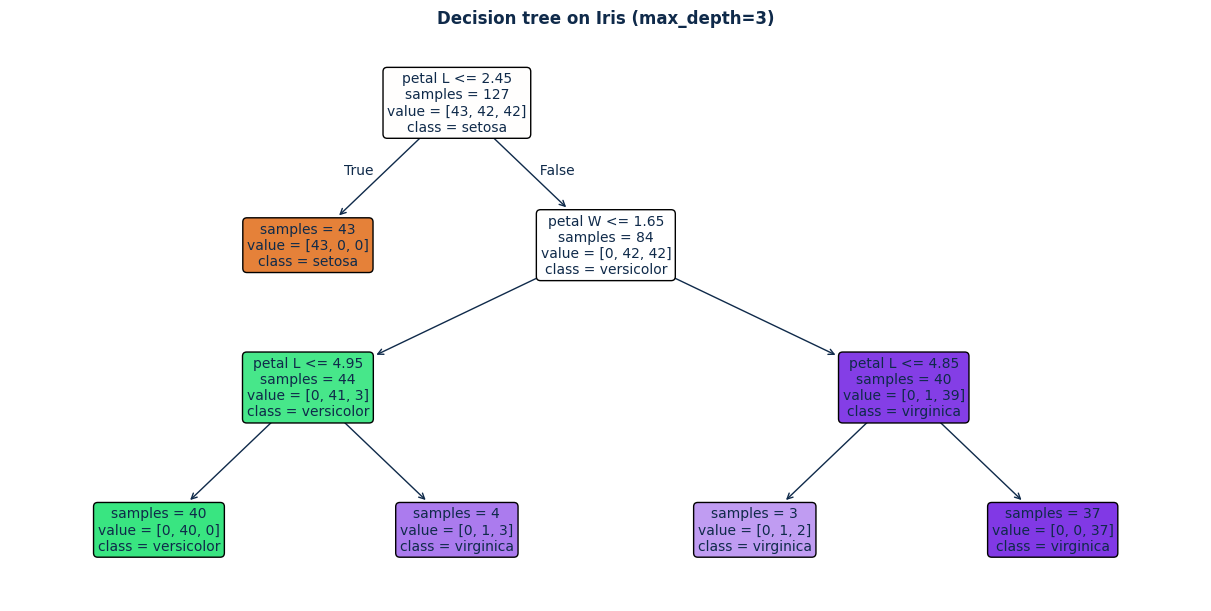

In [5]:
# ترسیم درخت Iris با plot_tree — هر برگ یک کلاس نهایی است
fig, ax = plt.subplots(figsize=(12,6), layout="constrained")
plot_tree(tree, feature_names=["sepal L","sepal W","petal L","petal W"],
          class_names=list(iris.target_names), filled=True, rounded=True,
          fontsize=10, impurity=False, ax=ax)
ax.set_title("Decision tree on Iris (max_depth=3)")
plt.show()

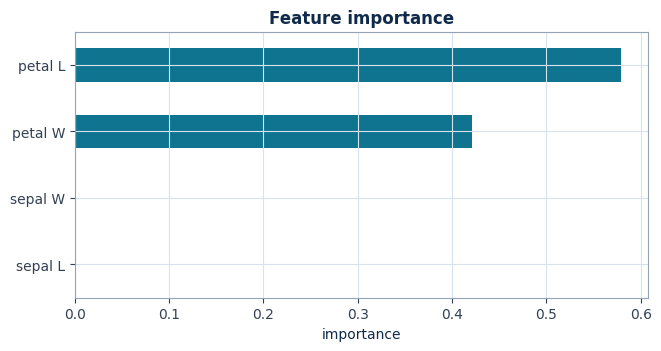

sepal L    0.000
sepal W    0.000
petal W    0.421
petal L    0.579
dtype: float64


In [6]:
# اهمیت ویژگی‌ها (feature importance): گلبرگ‌ها تقریباً همهٔ تصمیم را می‌گیرند
imp = pd.Series(tree.feature_importances_,
                  index=["sepal L","sepal W","petal L","petal W"]).sort_values()
fig, ax = plt.subplots(figsize=(6.5,3.4), layout="constrained")
imp.plot.barh(color=[TEAL if v>0 else "#CBD5E1" for v in imp], ax=ax)
ax.set_title("Feature importance"); ax.set_xlabel("importance")
plt.show()
print(imp.round(3))

<div dir="rtl" style="text-align:right; font-family:Tahoma, sans-serif; line-height:1.9">
<h2 style="color:#0F2A4A">جمع‌بندی</h2>
<ul><li>درخت با ویژگی‌ای شاخه می‌زند که بیشترین Gain (کاهش ناخالصی) را بدهد</li><li>خودش کشف کرد گلبرگ مهم است و کاسبرگ تقریباً بی‌اهمیت (۰٪)</li><li>max_depth را تغییر دهید: عمق بیشتر = خطر بیش‌برازش</li></ul>
<p style="color:#45607A">قدم بعدی: پارامترها (مثل k یا max_depth) را تغییر دهید و اثرشان را روی خروجی ببینید.</p>
</div>